In [12]:
import numpy as np
f= open("data.txt", 'r')
data=[]
for line in f:
    data.append(line.strip())
n=int(data[0])
m=float(data[1])
a=float(data[2])
T_0=float(data[3])
f.close()
N=n**3

In [13]:
r=np.empty((N,3))
p=np.empty((N,3))

In [14]:
b_0=np.array([a,0.,0.])
b_1=np.array([a/2., np.sqrt(3.)/2.*a,0.])
b_2=np.array([a/2., np.sqrt(3.)/6.*a, np.sqrt(2./3.)*a])
rng_i = np.arange(0,n,1)
i=[]
for i0 in rng_i:
    for i1 in rng_i:
        for i2 in rng_i:
            i_=i0+i1*n+i2*n**2           
            r[i_]=(i0-(n-1)/2)*b_0+(i1-(n-1)/2)*b_1+(i2-(n-1)/2)*b_2 
            i.append(i_)

In [15]:
r_sr=np.sum(r,axis=0)/N

In [16]:
file_initial=open('initial.xyz','w')
file_initial.write(f"{N}\n?\n")
for ll in range(N):
    file_initial.write(f"Ar {r[ll][0]} {r[ll][1]} {r[ll][2]} \n")
file_initial.close()

In [17]:
kb=8.31e-3
if T_0 == 0:
    p=np.zeros((N,3))
    Ekin_scaled=np.zeros((N,3))
else:
    lmb=1.0-np.random.rand(N,3)
    Ekin=-0.5*kb*T_0*np.log(lmb)
    E_sr_los=np.sum(Ekin)/3/N
    Ekin_scaled=Ekin*(0.5*kb*T_0/E_sr_los)
    s=np.random.choice([-1.0,1.0], size=(N,3))
    p=s*np.sqrt(2*m*Ekin_scaled)


In [18]:
P_tot=sum(p)
p_scaled=p-P_tot/N
np.savetxt('momenta.dat', p_scaled, delimiter='\t', header='px\tpy\tpz')

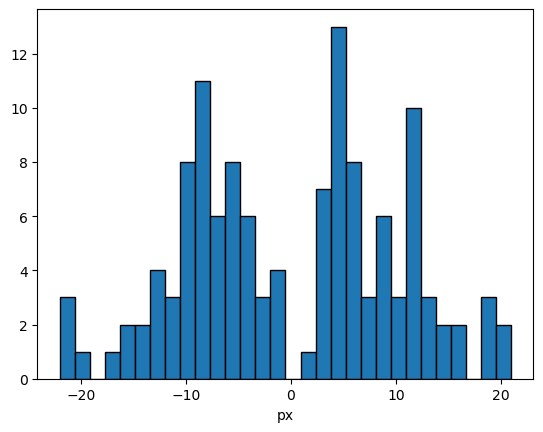

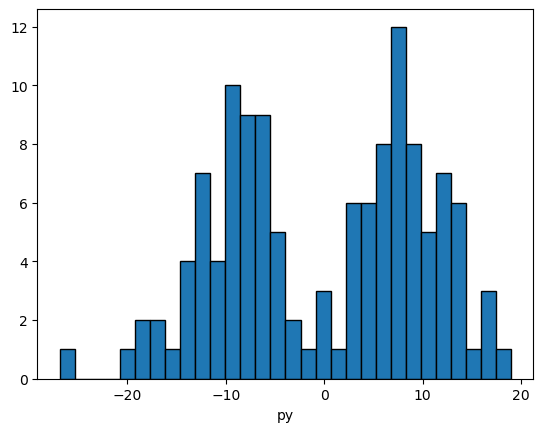

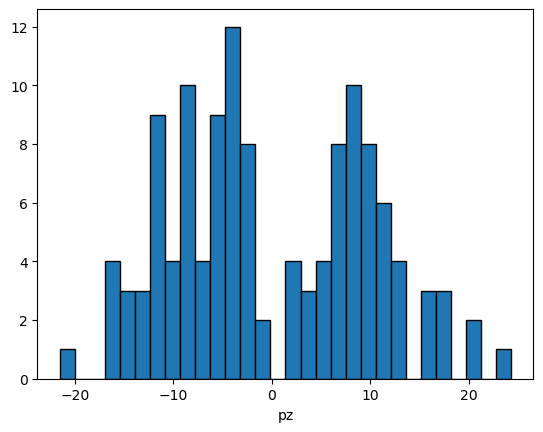

In [19]:
import matplotlib.pyplot as plt
px=p_scaled[:,0]
py=p_scaled[:,1]
pz=p_scaled[:,2]
plt.hist(px, bins=30, edgecolor='black')
plt.xlabel('px')
plt.show()
plt.hist(py, bins=30, edgecolor='black')
plt.xlabel('py')
plt.show()
plt.hist(pz, bins=30, edgecolor='black')
plt.xlabel('pz')
plt.show()

In [20]:
suma_p_scaled=sum(p_scaled)

In [22]:
file_diagnostyka_1=open('diagnostyka1.txt','w')
file_diagnostyka_1.write(f'całkowita liczba atomów = {N}\n')
file_diagnostyka_1.write(f'wektor średniego przesunięcia r_x={r_sr[0]}, r_y={r_sr[1]}, r_z={r_sr[2]}\n')
file_diagnostyka_1.write(f'energia kinetyczna przed usunięciem ruchu środka masy = {1.5*N*kb*T_0}\n')
file_diagnostyka_1.write(f'suma pędów przed korektą {sum(p)}\n')
file_diagnostyka_1.write(f'suma pędów po korekcie {suma_p_scaled}\n')
file_diagnostyka_1.close()